In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["ABSL_MIN_LOG_LEVEL"] = "3"
import warnings
import datetime
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from keras.layers import Dense, Conv2D, MaxPool2D,Flatten, Input,Dropout
import seaborn as sns
import visualkeras
from visualkeras.lenet import lenet_view
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay , classification_report ,accuracy_score, precision_score, recall_score, f1_score , roc_curve , auc
from pathlib import Path
from tensorflow.keras import layers
from tensorflow.keras.utils import plot_model
from sklearn.preprocessing import label_binarize


warnings.filterwarnings(
    "ignore",
    message="The legend_text_spacing_offset parameter is deprecated.*",
    category=UserWarning,
    module="visualkeras.layered"
)


In [3]:
# data
df_train= pd.read_csv('../data/sign_mnist_train.csv')
df_test= pd.read_csv('../data/sign_mnist_test.csv')

In [4]:
# drop label train and test
X_train= df_train.drop(columns='label')
y_train= df_train['label']

# test
X_test= df_test.drop(columns='label')
y_test= df_test['label']


In [5]:
EPOCHS=30
BATCH_SIZE=64

In [6]:
# funcion split train and test
def split(X_data, y_data):
    np.random.seed(42)
    tf.keras.utils.set_random_seed(42)
    X_train, x_val, y_train, y_val= train_test_split(
        X_data,y_data,
        test_size=0.2,
        random_state=42,
        stratify=y_data
    )
    return X_train, x_val, y_train, y_val

In [7]:
X_train, x_val, y_train, y_val= split(X_train, y_train)

In [8]:
# pasar de 784 a 4 dimensiones
X_train_res= X_train.values.reshape(-1,28,28,1).astype('float32')
x_val_res= x_val.values.reshape(-1,28,28,1).astype('float32')
X_test_res= X_test.values.reshape(-1,28,28,1).astype('float32')

In [9]:
train_dataset= (
    tf.data.Dataset.from_tensor_slices((X_train_res, y_train))
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_dataset= (
    tf.data.Dataset.from_tensor_slices((x_val_res, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
test_dataset= (
    tf.data.Dataset.from_tensor_slices((X_test_res, y_test))
    .batch(BATCH_SIZE)
)

## Build Neuronal networks CNN baseline and techniques of regularization

In [ ]:
# Build Baseline with earlystopping patience 5
baseline = tf.keras.Sequential(name='baseline', layers=[
    tf.keras.layers.Input(shape=(28,28,1), name='Input_layer_Dense'),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(64,(3,3), activation='relu', name='layer_conv'),
    tf.keras.layers.MaxPool2D((2,2), name='Maxpool2D'),
    tf.keras.layers.Flatten(name='flatten'),
    tf.keras.layers.Dense(128, activation='relu', name='layer_Dense_intermediate'),
    tf.keras.layers.Dense(25, activation='softmax', name='Output_layer')
])
baseline.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_conv (Conv2D)             │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Maxpool2D (MaxPooling2D)        │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_Dense_intermediate        │ (None, 128)            │     1,384,576 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_layer (Dense)            │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,388,441 (5.30 MB)

 Trainable params: 1,388,441 (5.30 MB)

 Non-trainable params: 0 (0.00 B)

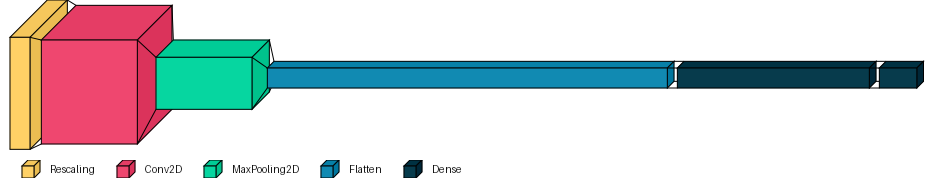

In [27]:
visualkeras.layered_view(baseline, legend=True, draw_volume=True)


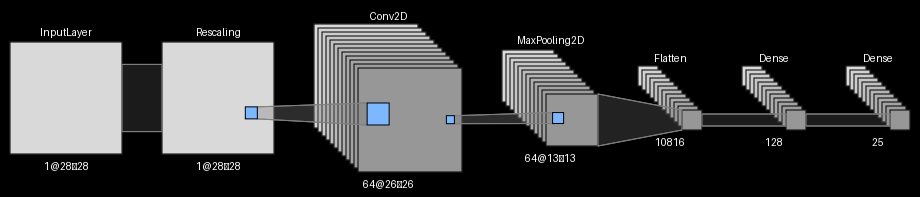

In [12]:
visualkeras.lenet_view(baseline)

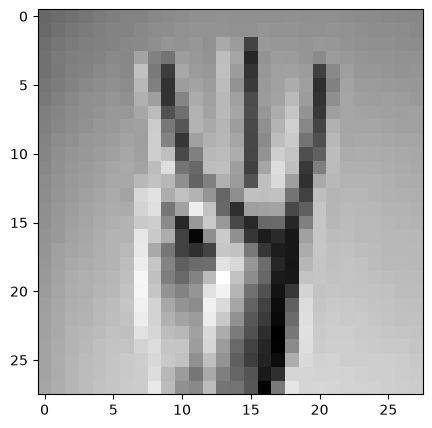

In [13]:
# imagen normal
plt.figure(figsize=(6,5))
plt.imshow(X_train_res[0], cmap='gray')
plt.show()

In [14]:
# Build CNn_regularization
cnn_reg= tf.keras.Sequential(name='cnn_reg', layers=[
    tf.keras.layers.Input(shape=(28,28,1), name='Input_layer'),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(64,(3,3), name='layer_conv2D'),
    tf.keras.layers.MaxPool2D((2,2), name='layer_maxpool'),
    tf.keras.layers.Flatten(name='flatten'),
    tf.keras.layers.Dense(128, activation='relu', name='layer_intermediate'),
    tf.keras.layers.Dropout(0.2, name='Dropout_0.2'),
    tf.keras.layers.Dense(25, activation='softmax', name='layer_output')
])
cnn_reg.summary()

Model: "cnn_reg"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_conv2D (Conv2D)           │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_maxpool (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_intermediate (Dense)      │ (None, 128)            │     1,384,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_0.2 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_output (Dense)            │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,388,441 (5.30 MB)

 Trainable params: 1,388,441 (5.30 MB)

 Non-trainable params: 0 (0.00 B)

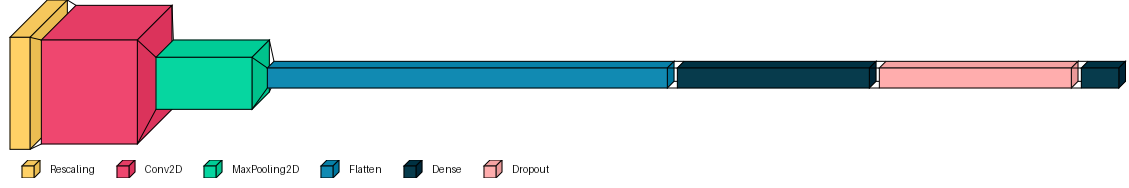

In [ ]:
visualkeras.layered_view(cnn_reg, legend=True, draw_volume=True)


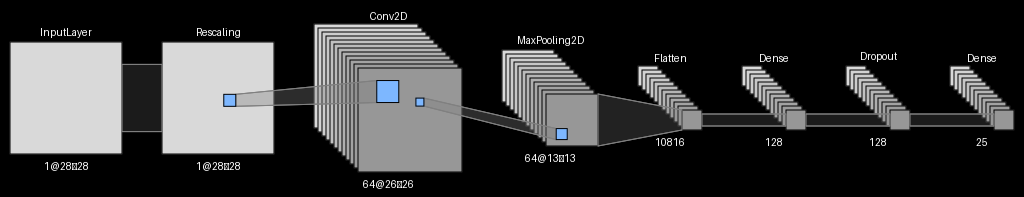

In [16]:
visualkeras.lenet_view(cnn_reg)

# Red_C
> la siguiente red contendra 3 tipos de tecnicas de regularizacion de data augmentetion que son las siguientes; Rotation, Escalado que corresponde a las transformaciones geometricas, la otra tecnica que se aplicara es aumento del espacio de color; contraste.

> rotation, parametros aplicados, factor 0.03 , randomzoom height=-0.05, 0.05, widhtfactor=-0.05, 0.05
> batch normalization, lo que hace es que toma las activaciones (salidas numericas) de una capa y las normaliza, cada entrada donde le ajusta la media y la varianza, en tiempo real para cada lote antes de pasarlas al siguiente capa.

In [17]:
# Build convolutional network red_c
red_c = tf.keras.Sequential(name='red_c', layers=[
    tf.keras.layers.Input(shape=(28,28,1),name='layers_input'),
    tf.keras.layers.Rescaling(1./255),
    
    # data augmentation
    tf.keras.layers.RandomRotation(factor=0.03, name='aug_rotation'),
    tf.keras.layers.RandomZoom(height_factor=(-0.05,0.05), width_factor=(-0.05,0.05), name='aug_zoom'),

    # tecnica aumeto del espacio de color, contraste
    tf.keras.layers.RandomContrast(factor=0.1, name='aug_contrast'),

    # convolutional network
    tf.keras.layers.Conv2D(64,(3,3), name='layer_conv2D'),
    tf.keras.layers.BatchNormalization(name='batch_norma_1'),
    tf.keras.layers.MaxPool2D((2,2), name='layer_Maxpool2D'),
    tf.keras.layers.Flatten(name='layer_flatten'),
    
    tf.keras.layers.Dense(128, activation='relu', name='layer_Dense'),
    tf.keras.layers.Dropout(0.2, name='dropout_0.2'),
    tf.keras.layers.Dense(25, activation='softmax', name='layer_output'),
    ])
red_c.summary()

Model: "red_c"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rotation (RandomRotation)   │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_zoom (RandomZoom)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_contrast (RandomContrast)   │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_conv2D (Conv2D)           │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norma_1                   │ (None, 26, 26, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_Maxpool2D (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_flatten (Flatten)         │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_Dense (Dense)             │ (None, 128)            │     1,384,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_0.2 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_output (Dense)            │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,388,697 (5.30 MB)

 Trainable params: 1,388,569 (5.30 MB)

 Non-trainable params: 128 (512.00 B)

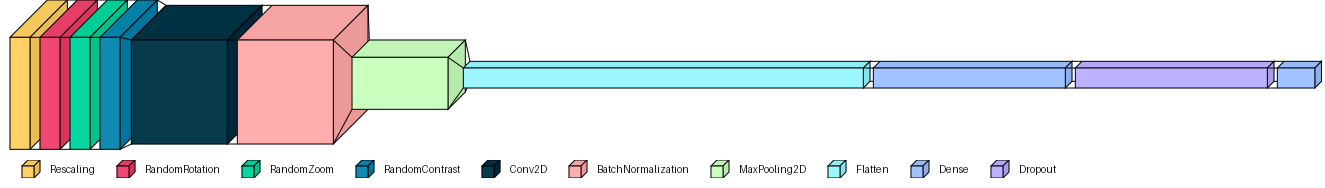

In [18]:
visualkeras.layered_view(red_c, legend=True, draw_volume=True)

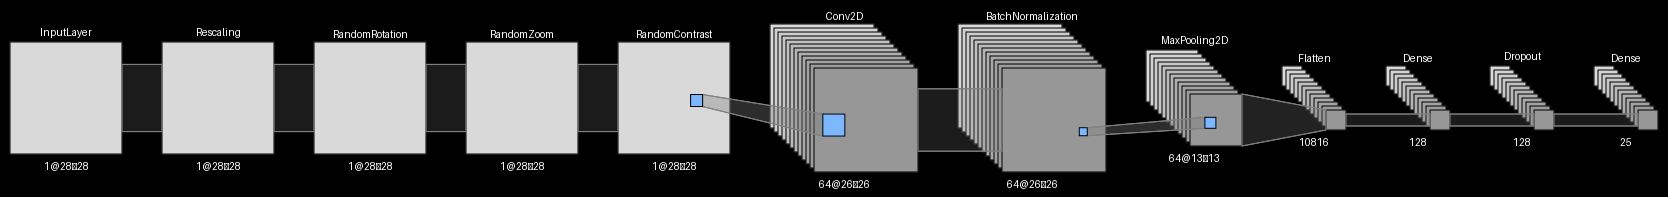

In [19]:
visualkeras.lenet_view(red_c)

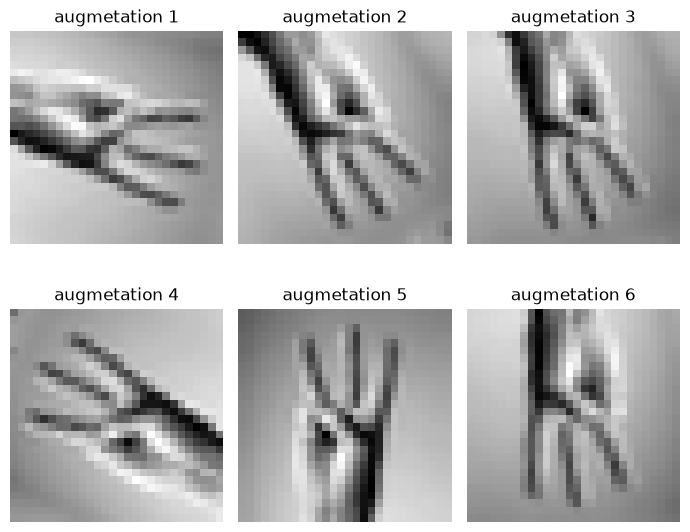

In [20]:
# image rototation display
data_aug= tf.keras.Sequential([
    tf.keras.layers.RandomRotation(factor=0.6),
    tf.keras.layers.RandomContrast(factor=0.1),
    tf.keras.layers.RandomZoom(height_factor=(-0.05,0.05), width_factor=(-0.05,0.05))
], name='data_aug_block')

image = X_train_res[0]
image_batch= tf.expand_dims(image, 0)

plt.figure(figsize=(7,6))
for i in range(6):
    augmentation_image= data_aug(image_batch)
    ax= plt.subplot(2, 3, i+1)
    plt.imshow(augmentation_image.numpy()[0], cmap='gray')
    plt.title(f'augmetation {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()



In [ ]:
# model list
model=[baseline, cnn_reg, red_c]
callbacks_TensorBoard={}
for mod in model:
    log_dir= f'log/fit_{mod.name}_{datetime.datetime.now().strftime("%d-%m-%y,%H-%M-%S")}'
    callbacks_ear_stopp= tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    callbacks_TensorBoard[mod.name]= tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

In [ ]:
def compile_and_fit(model, X_train, y_train, x_val, y_val):
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    histories= model.fit(
        train_dataset,
        epochs=EPOCHS,
        validation_data=val_dataset,
        callbacks=[callbacks_ear_stopp, callbacks_TensorBoard[model.name]],
        verbose=0
    )
    return model, histories 

In [23]:
# modelo base compile and fit
model_base, histories_base= compile_and_fit(baseline, X_train, y_train, x_val, y_val)

/home/roac/Documents/Duoc26/Tecnicas avanzadas de Machine Learning/EA3/CNN_regularizacion/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


In [32]:
# model cnn dropout + earlystopping
model_cnn_drop, histories_cnn_drop = compile_and_fit(cnn_reg, X_train, y_train, x_val, y_val)

/home/roac/Documents/Duoc26/Tecnicas avanzadas de Machine Learning/EA3/CNN_regularizacion/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


In [33]:
# model red_C full regularization
model_full, histories_full =compile_and_fit(red_c, X_train, y_train, x_val, y_val)

In [34]:
# guardar modelos formato .keras
model_dir= '../model'
os.makedirs(model_dir, exist_ok=True)
model=[baseline, cnn_reg, red_c]
for mod in model:
    nombre_archivo= f'{mod.name}.keras'
    ruta_completa= os.path.join(model_dir, nombre_archivo)
    mod.save(ruta_completa)
    print(f'Modelo {mod.name} guardado correctamente en ruta {ruta_completa}')

Modelo baseline guardado correctamente en ruta ../model/baseline.keras
Modelo cnn_reg guardado correctamente en ruta ../model/cnn_reg.keras
Modelo red_c guardado correctamente en ruta ../model/red_c.keras


In [ ]:
# gap
train_loss, train_acc = baseline.evaluate(test_dataset, verbose=0)
val_loss, val_acc= baseline.evaluate(val_dataset, verbose=0)

gap_baseline= train_acc - val_acc
message= f'!La brecha es igual o menor a 1.5%, esto indica que el modelo {baseline.name}, generaliza correctamente' if gap_baseline <= 0.015 else 'hay sobreajuste'
print(f'''
Train accuracy: {train_acc:.3f}
Val accuracy:   {val_acc:.3f}
val loss:       {val_loss:.3f}
gap:            {gap_baseline:.3f}
brecha:         {message}''')


Train accuracy: 0.826
Val accuracy:   1.000
val loss:       0.000
gap:            -0.174
brecha:         !La brecha es igual o menor a 1.5%, esto indica que el modelo baseline, generaliza correctamente


In [36]:
train_loss, train_acc= cnn_reg.evaluate(test_dataset, verbose=0)
val_loss, val_acc= cnn_reg.evaluate(val_dataset, verbose=0)

gap= train_acc - val_acc
message= f'!La brecha es igual o menor a 1.5%, esto indica que el modelo {baseline.name}, generaliza correctamente' if gap <= 0.015 else 'hay sobreajuste'
print(f'''
Train accuracy: {train_acc:.3f}
Val accuracy:   {val_acc:.3f}
val loss:       {val_loss:.3f}
gap:            {gap:.3f}
brecha:         {message}''')


Train accuracy: 0.853
Val accuracy:   1.000
val loss:       0.000
gap:            -0.147
brecha:         !La brecha es igual o menor a 1.5%, esto indica que el modelo baseline, generaliza correctamente


In [37]:
train_loss, train_acc= red_c.evaluate(test_dataset, verbose=0)
val_loss, val_acc= red_c.evaluate(val_dataset, verbose=0)

gap_full= train_acc - val_acc
message= f'!La brecha es igual o menor a 1.5%, esto indica que el modelo {baseline.name}, generaliza correctamente' if gap <= 0.015 else 'hay sobreajuste'
print(f'''
Train accuracy: {train_acc:.3f}
Val accuracy:   {val_acc:.3f}
val loss:       {val_loss:.3f}
gap:            {gap_full:.3f}
brecha:         {message}''')


Train accuracy: 0.868
Val accuracy:   0.997
val loss:       0.010
gap:            -0.129
brecha:         !La brecha es igual o menor a 1.5%, esto indica que el modelo baseline, generaliza correctamente


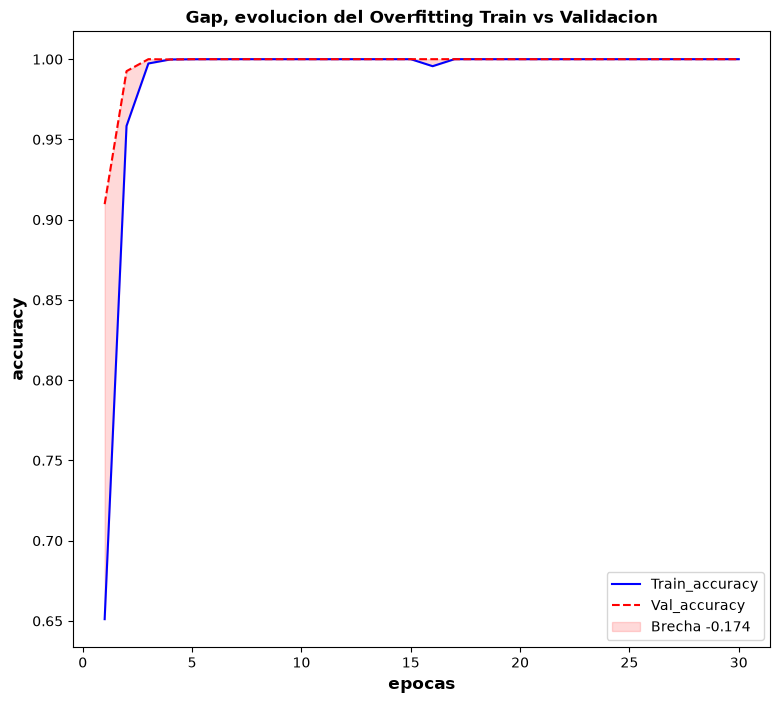

In [38]:
# grafico gap red baseline y red_c
plt.figure(figsize=(9,8))
epochs= range(1, len(histories_base.history['accuracy'])+1)
plt.plot(epochs,histories_base.history['accuracy'],label='Train_accuracy',color='blue',linestyle='-')
plt.plot(epochs,histories_base.history['val_accuracy'],label='Val_accuracy',color='red',linestyle='--')
plt.fill_between(epochs,histories_base.history['accuracy'],histories_base.history['val_accuracy'],color='red',alpha=0.15,label=f'Brecha {gap_baseline:.3f}',)
plt.title('Gap, evolucion del Overfitting Train vs Validacion',fontsize=12, fontweight='bold')
plt.xlabel('epocas',fontsize=12,fontweight='bold')
plt.ylabel('accuracy',fontsize=12,fontweight='bold')
plt.legend(loc='lower right')
plt.show()

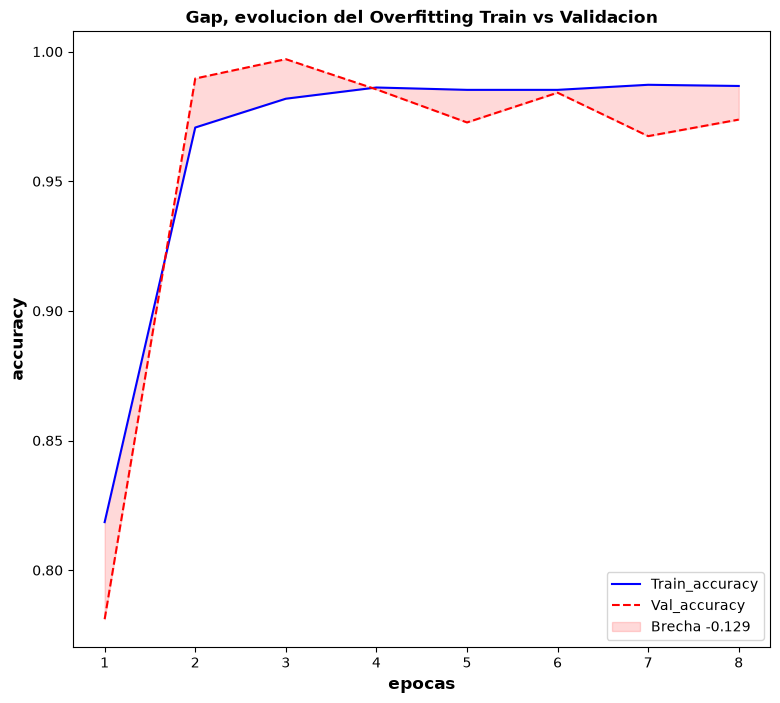

In [39]:
plt.figure(figsize=(9,8))
epochs= range(1, len(histories_full.history['accuracy'])+1)
plt.plot(epochs,histories_full.history['accuracy'],label='Train_accuracy',color='blue',linestyle='-')
plt.plot(epochs,histories_full.history['val_accuracy'],label='Val_accuracy',color='red',linestyle='--')
plt.fill_between(epochs,histories_full.history['accuracy'],histories_full.history['val_accuracy'],color='red',alpha=0.15,label=f'Brecha {gap_full:.3f}',)
plt.title('Gap, evolucion del Overfitting Train vs Validacion',fontsize=12, fontweight='bold')
plt.xlabel('epocas',fontsize=12,fontweight='bold')
plt.ylabel('accuracy',fontsize=12,fontweight='bold')
plt.legend(loc='lower right')
plt.show()

In [ ]:
y_predict_probs= cnn_reg.predict(test_dataset)
y_predict_clases= np.argmax(y_predict_probs, axis=1)

y_true= y_test.values if hasattr(y_test, 'values') else np.array(y_test)
print(classification_report(y_true, y_predict_clases))

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       331
           1       0.95      0.94      0.95       432
           2       1.00      0.93      0.96       310
           3       0.99      0.92      0.95       245
           4       0.95      0.96      0.95       498
           5       0.92      1.00      0.96       247
           6       0.82      0.80      0.81       348
           7       0.81      0.91      0.86       436
           8       0.92      0.84      0.88       288
          10       0.70      0.57      0.63       331
          11       0.91      1.00      0.95       209
          12       0.85      0.89      0.87       394
          13       0.90      0.71      0.79       291
          14       1.00      0.91      0.96       246
          15       0.93      0.95      0.94       347
          16       0.66      0.87      0.75       164
          17       0.29      0.48      

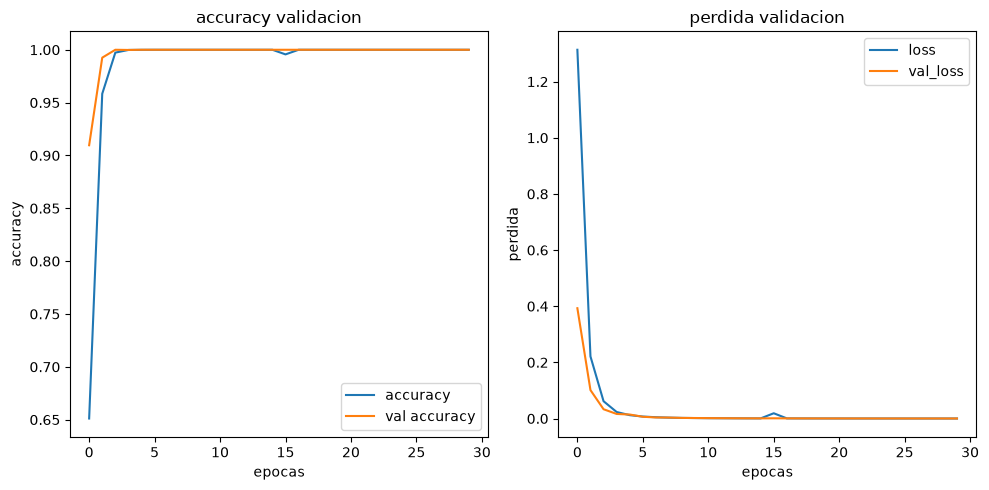

In [41]:
# baseline
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(histories_base.history['accuracy'], label='accuracy')
plt.plot(histories_base.history['val_accuracy'], label='val accuracy')
plt.title('accuracy validacion')
plt.xlabel('epocas')
plt.ylabel('accuracy')
plt.legend(loc='lower right')

plt.subplot(1,2,2)
plt.plot(histories_base.history['loss'], label='loss')
plt.plot(histories_base.history['val_loss'], label='val_loss')
plt.title('perdida validacion')
plt.xlabel('epocas')
plt.ylabel('perdida')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


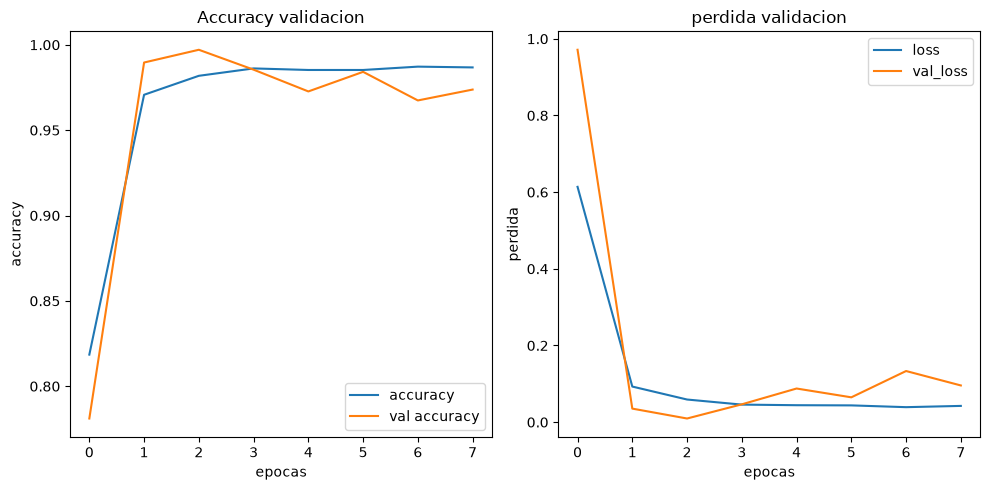

In [42]:
# red_c Compleja
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(histories_full.history['accuracy'], label='accuracy')
plt.plot(histories_full.history['val_accuracy'], label='val accuracy')
plt.title('Accuracy validacion')
plt.xlabel('epocas')
plt.ylabel('accuracy')
plt.legend(loc='lower right')

plt.subplot(1,2,2)
plt.plot(histories_full.history['loss'], label='loss')
plt.plot(histories_full.history['val_loss'], label='val_loss')
plt.title('perdida validacion')
plt.xlabel('epocas')
plt.ylabel('perdida')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [2]:
# visualizacion mediante tensorboard
%load_ext tensorboard
%tensorboard --logdir log/

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 12620), started 0:00:07 ago. (Use '!kill 12620' to kill it.)

# regularization
- random zoom, se aplica un factor del 0.05, es decir que la imagen se aleja y se acerca un 5% del tamano original.
- random contrast, 
- random rotation, 
